# 2 · TF-IDF vs. bge-m3 vs. LLM (zero-shot y few-shot), cascada y señales de confianza

Todos los enfoques se evalúan sobre **las mismas quejas** (conjunto común balanceado de quejas recientes).

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, Markdown, display

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
sys.path.insert(0, str(RAIZ))
from quejas import config
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 160)
R = json.loads((config.REPORTES / "resultados.json").read_text(encoding="utf-8"))
fig = lambda nombre: display(Image(filename=str(config.FIGURAS / nombre)))

## 2.1 · Comparación con IC 95 % y diferencias pareadas

,enfoque,n_quejas,f1_macro,f1_ic95_bajo,f1_ic95_alto,exactitud,exactitud_top2,brier_multiclase,ms_por_queja
0,1. TF-IDF + LR (25.722 ej.),300,0.825,0.779,0.865,0.827,0.933,0.255,0.098
1,1a. TF-IDF + LR (1.800 ej.),300,0.820,0.773,0.860,0.820,0.937,0.284,0.085
2,2. Zero-Shot prototipos bge-m3,300,0.690,0.639,0.737,0.693,0.837,0.532,788.692
3,3. bge-m3 + LR (1.800 ej.),300,0.798,0.752,0.842,0.800,0.900,0.298,788.692
4,4. LLM zero-shot (qwen2.5:7b),300,0.695,0.643,0.742,0.690,0.843,0.599,"13,941.797"
5,"5. LLM few-shot (qwen2.5:7b, 6 ej.)",300,0.799,0.754,0.842,0.800,0.893,0.399,"12,326.393"
6,6. Cascada TF-IDF → LLM zero-shot,300,0.830,0.787,0.867,0.830,0.907,0.315,"3,253.184"
7,7. Cascada TF-IDF → LLM few-shot,300,0.842,0.799,0.880,0.843,0.917,0.284,"2,876.256"


,enfoque_a,enfoque_b,diferencia,ic95_bajo,ic95_alto,distinguible
0,1. TF-IDF + LR (25.722 ej.),4. LLM zero-shot (qwen2.5:7b),0.131,0.072,0.190,True
1,1. TF-IDF + LR (25.722 ej.),"5. LLM few-shot (qwen2.5:7b, 6 ej.)",0.027,-0.022,0.075,False
2,"5. LLM few-shot (qwen2.5:7b, 6 ej.)",4. LLM zero-shot (qwen2.5:7b),0.104,0.059,0.152,True
3,3. bge-m3 + LR (1.800 ej.),4. LLM zero-shot (qwen2.5:7b),0.104,0.046,0.164,True
4,3. bge-m3 + LR (1.800 ej.),"5. LLM few-shot (qwen2.5:7b, 6 ej.)",-0.000,-0.047,0.046,False
5,1. TF-IDF + LR (25.722 ej.),3. bge-m3 + LR (1.800 ej.),0.027,-0.012,0.065,False
6,3. bge-m3 + LR (1.800 ej.),1a. TF-IDF + LR (1.800 ej.),-0.021,-0.063,0.021,False
7,7. Cascada TF-IDF → LLM few-shot,1. TF-IDF + LR (25.722 ej.),0.017,-0.018,0.051,False
8,6. Cascada TF-IDF → LLM zero-shot,1. TF-IDF + LR (25.722 ej.),0.005,-0.031,0.040,False
9,1. TF-IDF + LR (25.722 ej.),2. Zero-Shot prototipos bge-m3,0.136,0.079,0.189,True


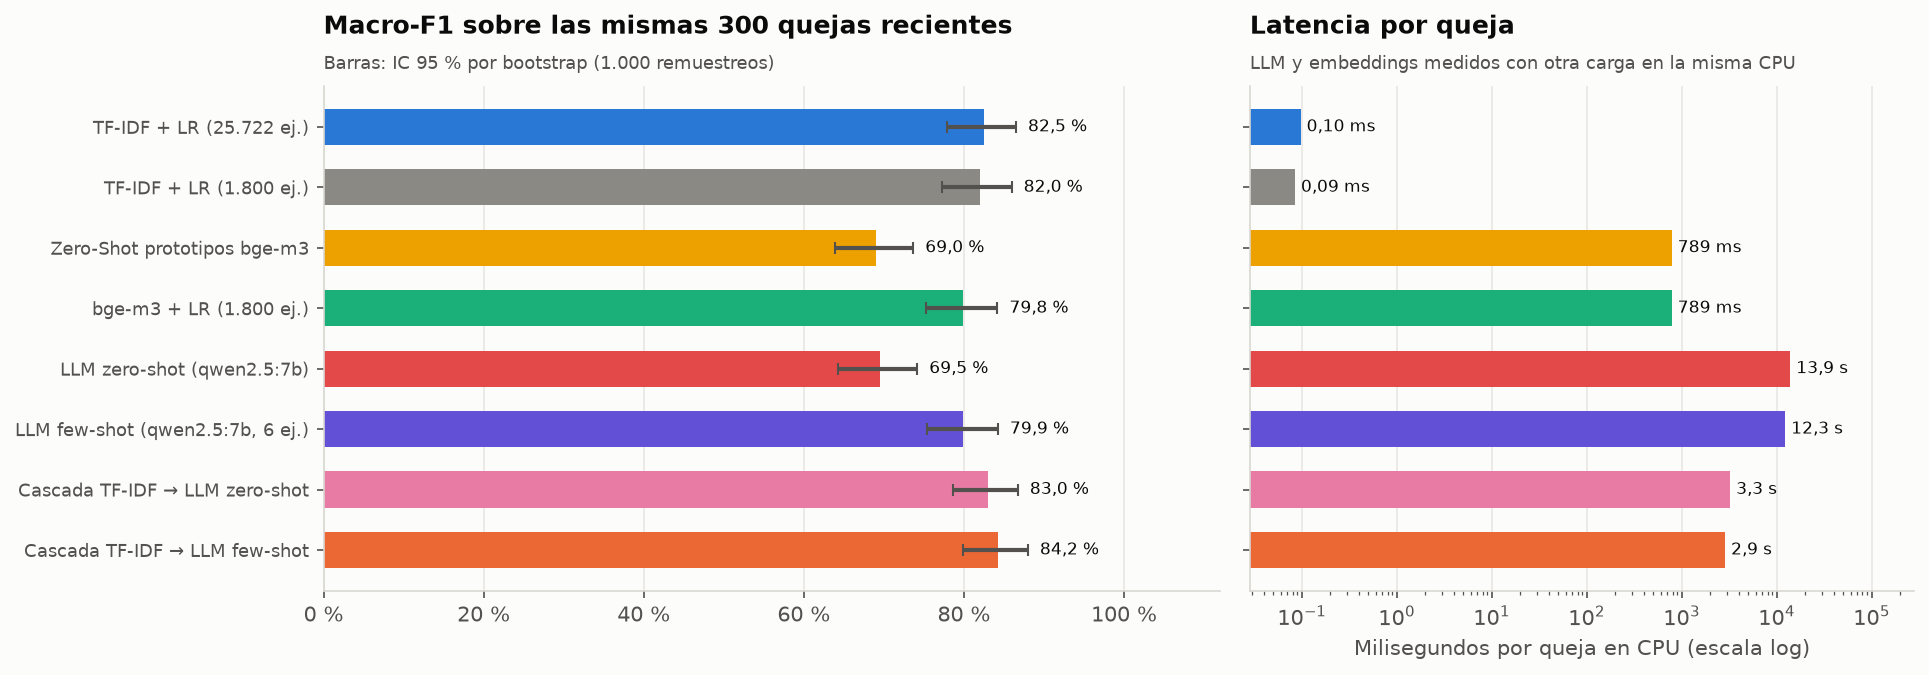

In [2]:
display(pd.read_csv(config.REPORTES / "comparacion_enfoques.csv")[["enfoque", "n_quejas", "f1_macro", "f1_ic95_bajo", "f1_ic95_alto", "exactitud", "exactitud_top2", "brier_multiclase", "ms_por_queja"]])
display(pd.read_csv(config.REPORTES / "diferencias_pareadas.csv"))
fig("02_comparacion_enfoques.png")

## 2.2 · Curva few-shot y matrices de confusión

,ejemplos_por_clase,total_ejemplos,f1_macro_bge_m3_media,f1_macro_bge_m3_std,f1_macro_tfidf_media,f1_macro_tfidf_std
0,2,12,0.459,0.016,0.394,0.059
1,5,30,0.598,0.046,0.520,0.027
2,10,60,0.703,0.023,0.635,0.008
3,30,180,0.753,0.012,0.712,0.021
4,100,600,0.790,0.006,0.778,0.003
5,300,1800,0.798,0.000,0.820,0.000


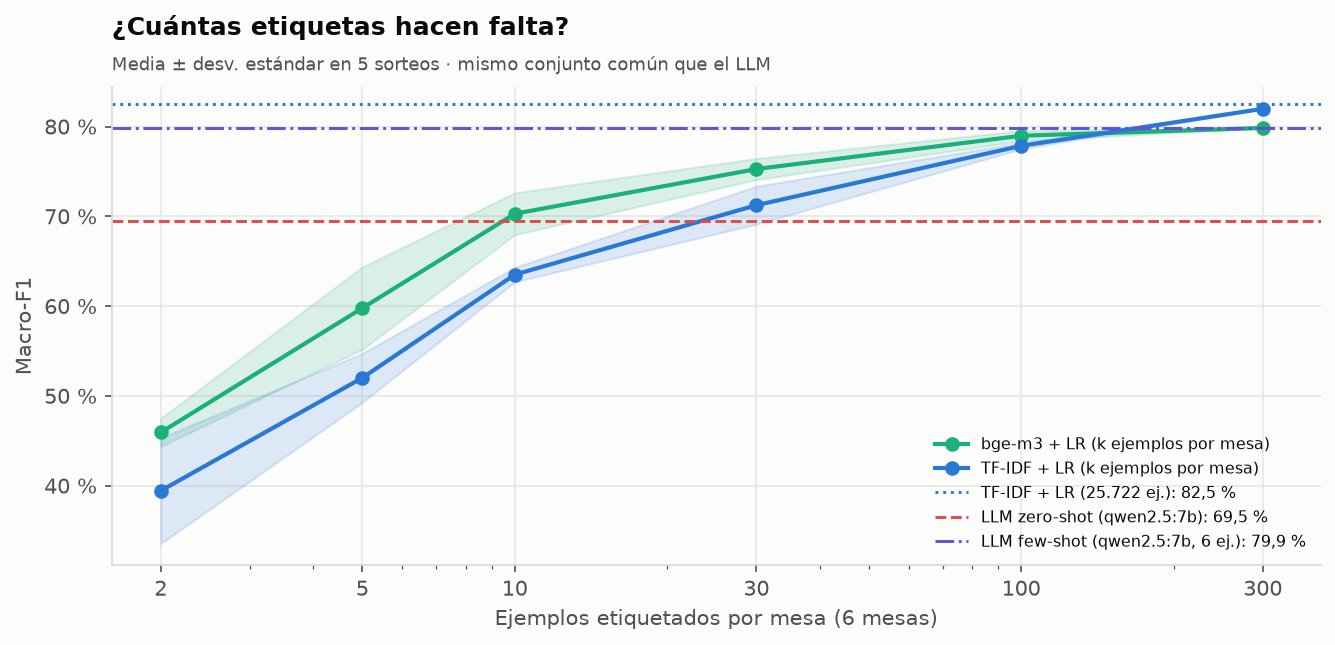

,enfoque,real,predicha,n,pct_de_errores
0,1. TF-IDF + LR (25.722 ej.),reporte_credito,prestamos_consumo,6,11.538
1,1. TF-IDF + LR (25.722 ej.),cobranza_deudas,reporte_credito,6,11.538
2,1. TF-IDF + LR (25.722 ej.),tarjetas_credito,cuentas_bancarias,6,11.538
3,1. TF-IDF + LR (25.722 ej.),reporte_credito,tarjetas_credito,4,7.692
23,4. LLM zero-shot (qwen2.5:7b),cobranza_deudas,reporte_credito,19,20.430
24,4. LLM zero-shot (qwen2.5:7b),tarjetas_credito,reporte_credito,16,17.204
25,4. LLM zero-shot (qwen2.5:7b),tarjetas_credito,cuentas_bancarias,6,6.452
26,4. LLM zero-shot (qwen2.5:7b),cuentas_bancarias,reporte_credito,6,6.452
44,"5. LLM few-shot (qwen2.5:7b, 6 ej.)",cobranza_deudas,reporte_credito,12,20.000
45,"5. LLM few-shot (qwen2.5:7b, 6 ej.)",reporte_credito,prestamos_consumo,5,8.333


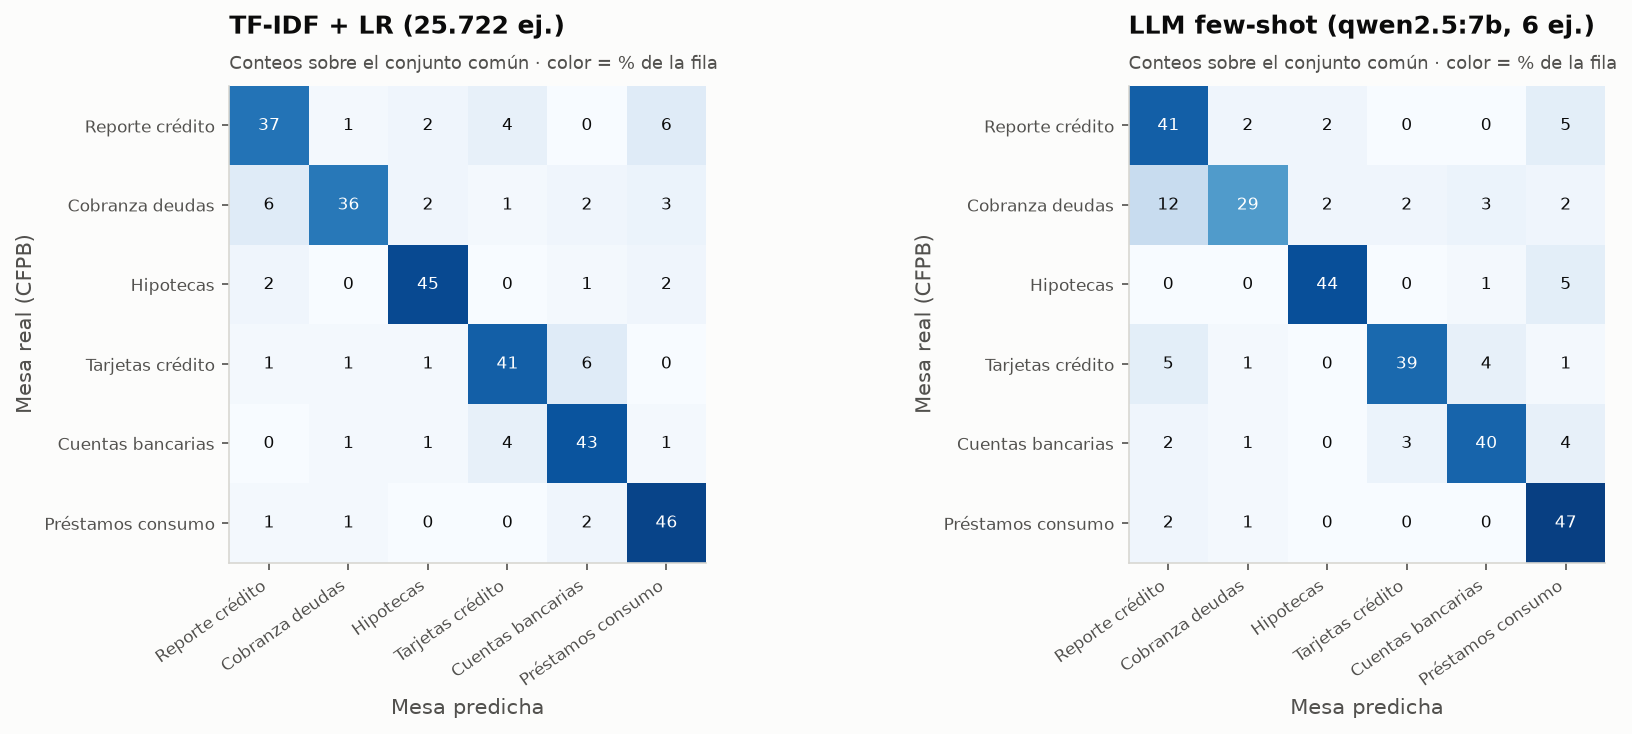

In [3]:
display(pd.read_csv(config.REPORTES / "curva_few_shot.csv"))
fig("03_curva_few_shot.png")
display(pd.read_csv(config.REPORTES / "confusiones_principales.csv").groupby("enfoque").head(4))
fig("05_matrices_confusion.png")

## 2.3 · Cascada TF-IDF → LLM

Umbral (fijado en validación): 0.7038 | % al LLM en prueba: 23.3


llm,few-shot,zero-shot
pct_al_llm,,
0.000,0.825,0.825
5.000,0.836,0.839
10.000,0.855,0.846
15.000,0.848,0.842
20.000,0.845,0.830
25.000,0.839,0.827
30.000,0.836,0.817
35.000,0.842,0.825
40.000,0.835,0.818


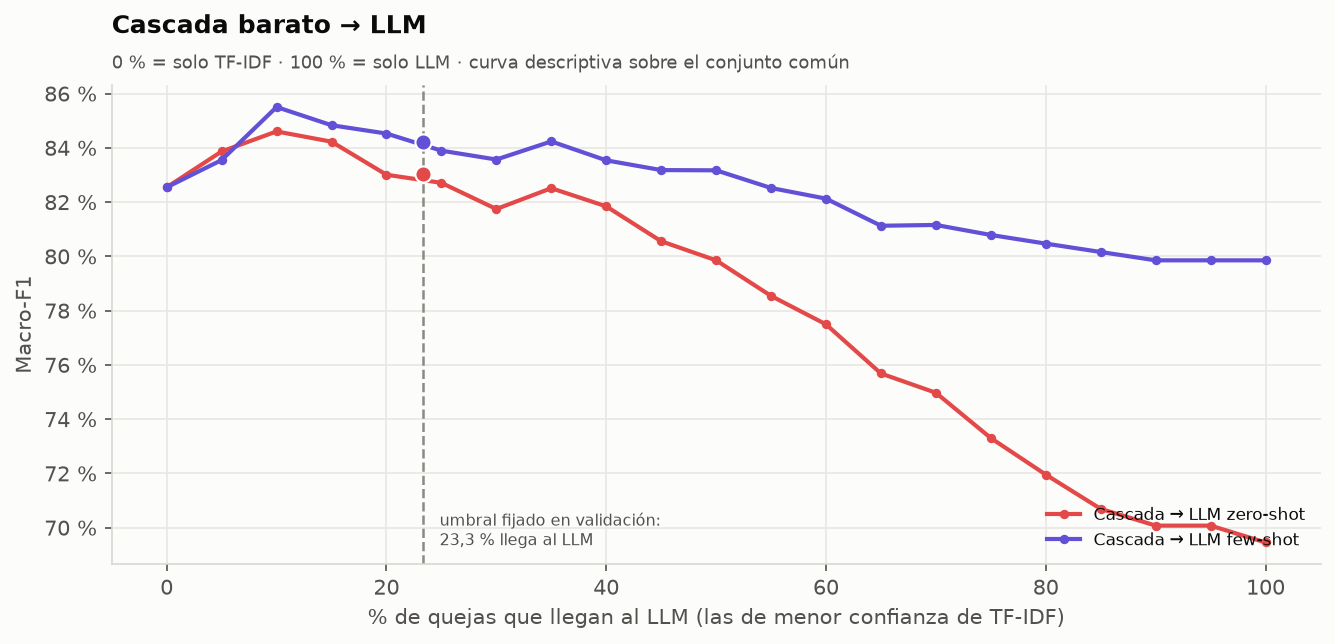

In [4]:
print("Umbral (fijado en validación):", round(R["cascada"]["umbral"], 4), "| % al LLM en prueba:", round(R["cascada"]["pct_al_llm_test"], 1))
display(pd.read_csv(config.REPORTES / "curva_cascada.csv").pivot(index="pct_al_llm", columns="llm", values="f1_macro"))
fig("06_cascada_tfidf_llm.png")

## 2.4 · Calibración, abstención y señales de confianza del LLM

,enfoque,temperatura,brier_sin_calibrar,brier_calibrado,ece_sin_calibrar,ece_calibrado,confianza_media_sin_calibrar,confianza_media_calibrado,exactitud
0,1. TF-IDF + LR (25.722 ej.),0.957,0.256,0.255,0.030,0.031,0.808,0.818,0.827
1,3. bge-m3 + LR (1.800 ej.),0.822,0.307,0.298,0.079,0.046,0.724,0.779,0.800
2,4. LLM zero-shot (qwen2.5:7b),NaN,0.599,NaN,0.275,NaN,0.889,NaN,0.690
3,"5. LLM few-shot (qwen2.5:7b, 6 ej.)",NaN,0.399,NaN,0.196,NaN,0.881,NaN,0.800


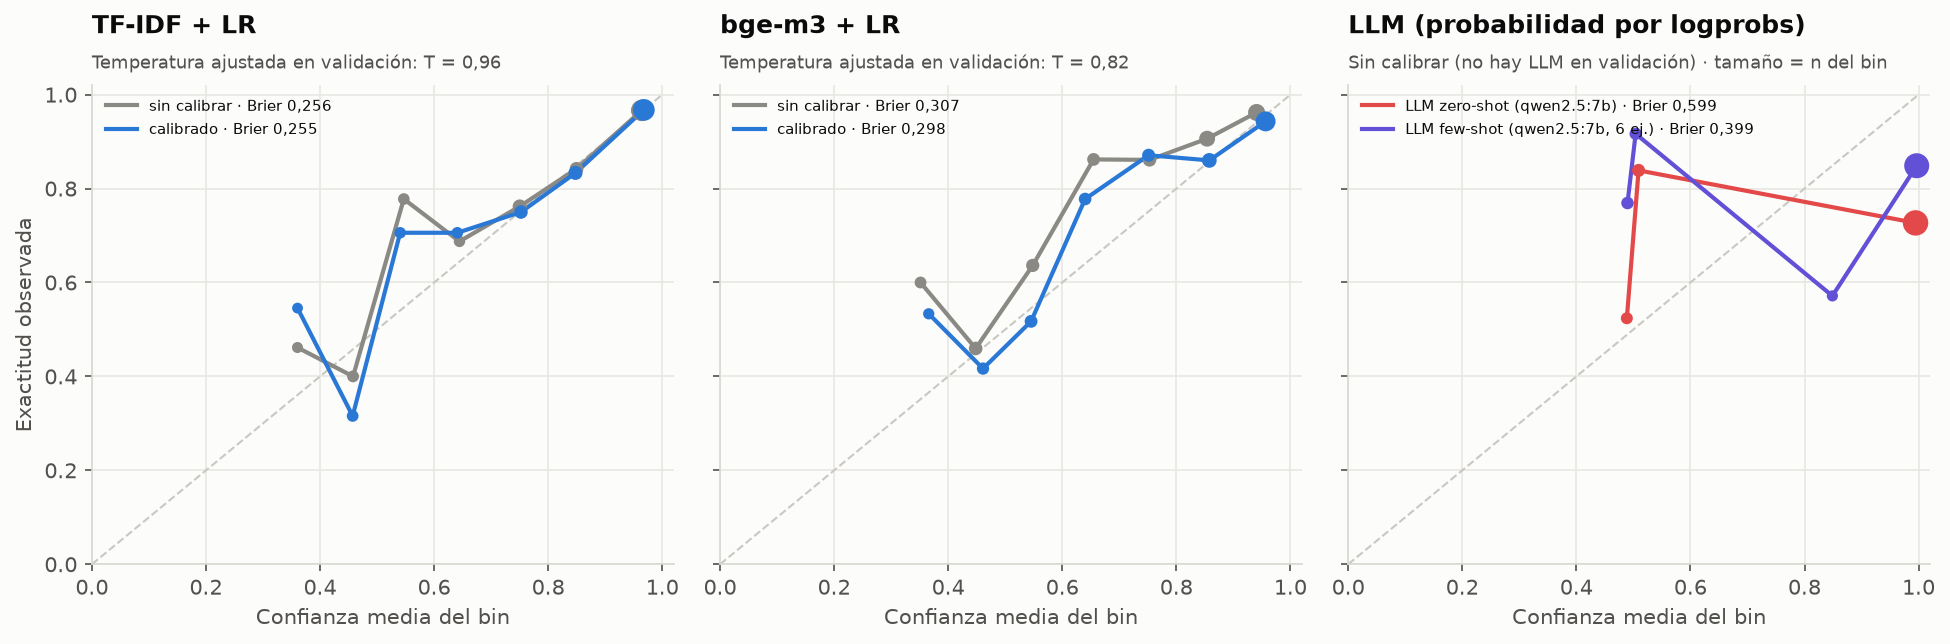

,enfoque,elegido_en,evaluado_en,umbral,cobertura_automatizada_pct,exactitud_sin_abstencion,exactitud_en_automatizadas,costo_operativo_1k_usd,costo_sin_abstencion_1k_usd,ahorro_pct
0,1. TF-IDF + LR (25.722 ej.),val_emb (n=600),test_comun (n=300),0.750,72.333,0.827,0.917,"1,808.333","2,426.667",25.481
1,3. bge-m3 + LR (1.800 ej.),val_emb (n=600),test_comun (n=300),0.775,60.333,0.800,0.917,"2,088.333","2,800.000",25.417


Experimento con la confianza escrita por el LLM: {'n_respuestas': 54, 'n_con_0_99': 53, 'valores_distintos': [0.85, 0.99]}


,llm,senal,auroc_acierto_vs_error,pct_con_senal_maxima
0,4. LLM zero-shot (qwen2.5:7b),Probabilidad de la ficha (logprobs del LLM),0.612,66.333
1,4. LLM zero-shot (qwen2.5:7b),Acuerdo zero-shot = few-shot,0.755,79.333
2,4. LLM zero-shot (qwen2.5:7b),Acuerdo LLM = TF-IDF,0.832,68.333
3,4. LLM zero-shot (qwen2.5:7b),Probabilidad calibrada de TF-IDF,0.610,12.667
4,"5. LLM few-shot (qwen2.5:7b, 6 ej.)",Probabilidad de la ficha (logprobs del LLM),0.662,65.333
5,"5. LLM few-shot (qwen2.5:7b, 6 ej.)",Acuerdo zero-shot = few-shot,0.569,79.333
6,"5. LLM few-shot (qwen2.5:7b, 6 ej.)",Acuerdo LLM = TF-IDF,0.762,80.333
7,"5. LLM few-shot (qwen2.5:7b, 6 ej.)",Probabilidad calibrada de TF-IDF,0.705,12.667


{'pct_acuerdo_zero_few': 79.33333333333333, 'exactitud_few_si_acuerdan': 0.8277310924369747, 'exactitud_few_si_discrepan': 0.6935483870967742, 'n_discrepan': 62}


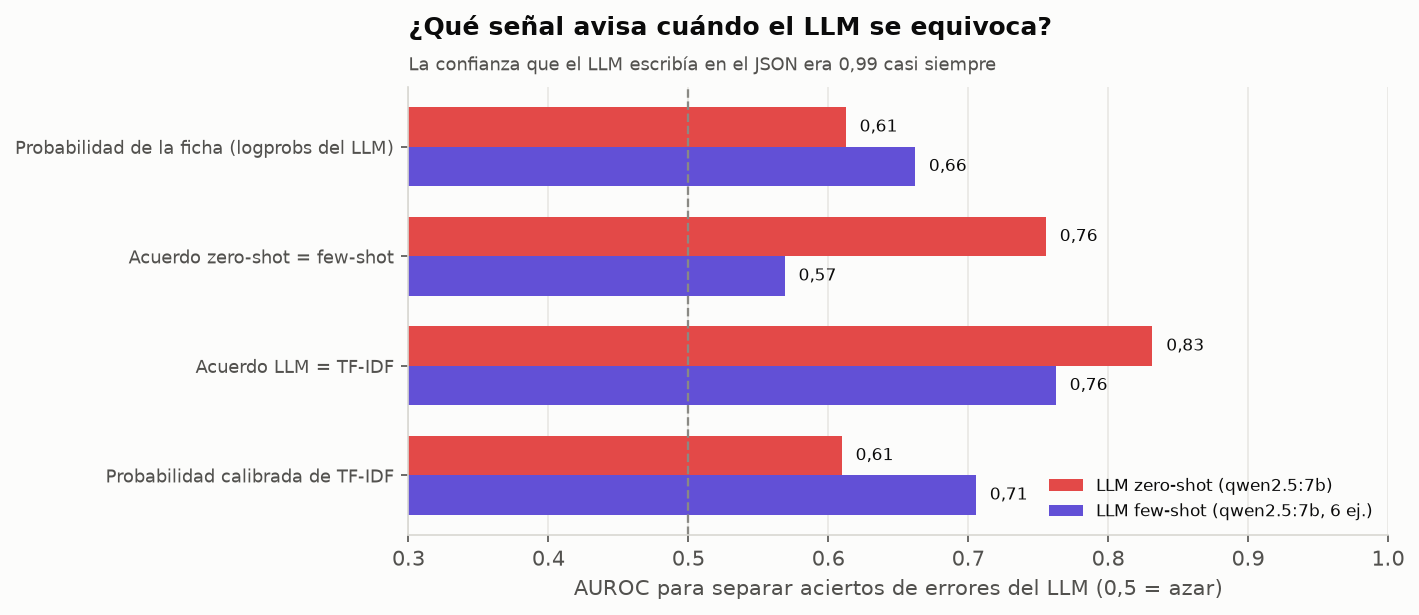

In [5]:
display(pd.read_csv(config.REPORTES / "calibracion.csv"))
fig("07_curvas_confiabilidad.png")
display(pd.read_csv(config.REPORTES / "abstencion_umbral_validacion.csv"))
print("Experimento con la confianza escrita por el LLM:", R["confianza_autodeclarada"])
display(pd.read_csv(config.REPORTES / "senales_confianza_llm.csv"))
print(R["acuerdo_zero_few"])
fig("08_senales_confianza_llm.png")